# Lab 2.2 - Train the Same Problem With TensorFlow/Keras (MNIST)

This notebook has `# TODO` markers (TODO 1-7). Work through them in order -
later cells depend on earlier ones (e.g. the hyperparameter sweep in Step 2
reuses the `build_model()` function you write in Step 1).

MNIST downloads automatically the first time you run this notebook (via
`tf.keras.datasets.mnist`) - no manual download needed, but you do need a
working internet connection the first time.

In [59]:
import time
import numpy as np
import tensorflow as tf
import tf_keras
import matplotlib.pyplot as plt

tf.random.set_seed(10)
np.random.seed(10)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 1 - Build and train a small CNN

Architecture (matches the lab diagram):

`Input 28x28x1 -> Conv2D(8, 3x3, ReLU) -> MaxPool(2x2) -> Conv2D(16, 3x3, ReLU) -> MaxPool(2x2) -> Flatten -> Dense(32, ReLU) -> Dense(10, Softmax)`

Kept small on purpose - this exact model gets quantized (2.3) and pruned +
deployed to the Pico (2.4).

Data loading and normalization are provided for you below.

In [60]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize to [0, 1] and add the channel dimension Conv2D expects
x_train = (x_train / 255.0).astype("float32")[..., np.newaxis]
x_test  = (x_test  / 255.0).astype("float32")[..., np.newaxis]

print("x_train:", x_train.shape, " x_test:", x_test.shape)

x_train: (60000, 28, 28, 1)  x_test: (10000, 28, 28, 1)


**TODO 1:** Complete `build_model()`. It should return a `tf_keras`
`Sequential` model with two conv+pool blocks feeding a small dense head,
matching the architecture above. The function takes some hyperparameters as
arguments - you'll reuse this same function for the experiments in Step 2,
so make sure each argument actually controls the thing its name says it does.

**Use `tf_keras`, not `tf.keras`, for every layer and the `Sequential` call.**
This is deliberate: `tf_keras` is the standalone legacy-Keras package (as
opposed to the Keras 3 that `tf.keras` points to by default). Building with
it now means Lab 2.3 can load this exact model directly for quantization,
including quantization-aware training, with no conversion step in between.

A couple of other things worth knowing before you write this:
- If `dropout > 0`, add a `Dropout` layer after the dense layer; if it's 0,
  skip it entirely (don't add a no-op layer in its place - an empty
  `tf_keras.layers.Layer()` doesn't have a working `call()` and will crash
  training).
- The output layer is always 10 units with softmax, regardless of the
  `activation` argument (that argument only controls the *hidden* layers).

In [61]:
def build_model(num_filters1=8, num_filters2=16, dense_units=32,
                 activation="relu", dropout=0.0):
    # TODO 1: build and return the Sequential model described above, using
    # tf_keras (not tf.keras) for every layer.
    layers = []
    return tf_keras.models.Sequential(layers)

# def build_model(activation="relu",
#                 num_filters1=8,
#                 num_filters2=16,
#                 dense_units=32,
#                 dropout=0.0):

#     layers = [
#         tf_keras.layers.Input(shape=(28, 28, 1)),

#         tf_keras.layers.Conv2D(
#             num_filters1,
#             (3, 3),
#             activation=activation
#         ),
#         tf_keras.layers.MaxPooling2D((2, 2)),

#         tf_keras.layers.Conv2D(
#             num_filters2,
#             (3, 3),
#             activation=activation
#         ),
#         tf_keras.layers.MaxPooling2D((2, 2)),

#         tf_keras.layers.Flatten(),

#         tf_keras.layers.Dense(
#             dense_units,
#             activation=activation
#         )
#     ]

#     if dropout > 0:
#         layers.append(tf_keras.layers.Dropout(dropout))

#     layers.append(
#         tf_keras.layers.Dense(10, activation="softmax")
#     )

#     return tf_keras.models.Sequential(layers)

#### We use this version of the function to train with different number of layers afterwards.
def build_model(activation="relu",
                num_filters1=8,
                num_filters2=16,
                num_filters3=32,
                num_conv_layers=2,
                dense_units=32,
                dense_units2=16,
                num_dense_layers=1,
                dropout=0.0):

    model = tf_keras.models.Sequential()
    model.add(tf_keras.layers.Input(shape=(28, 28, 1)))

    # First convolutional layer
    model.add(tf_keras.layers.Conv2D(
        num_filters1, (3, 3), activation=activation
    ))
    model.add(tf_keras.layers.MaxPooling2D((2, 2)))

    # Second convolutional layer (optional)
    if num_conv_layers >= 2:
        model.add(tf_keras.layers.Conv2D(
            num_filters2, (3, 3), activation=activation
        ))
        model.add(tf_keras.layers.MaxPooling2D((2, 2)))

    # Third convolutional layer (optional)
    if num_conv_layers >= 3:
        model.add(tf_keras.layers.Conv2D(
            num_filters3, (3, 3),
            padding="same",
            activation=activation
        ))

    model.add(tf_keras.layers.Flatten())

    # First hidden Dense layer
    model.add(tf_keras.layers.Dense(
        dense_units, activation=activation
    ))

    # Second hidden Dense layer (optional)
    if num_dense_layers >= 2:
        model.add(tf_keras.layers.Dense(
            dense_units2, activation=activation
        ))

    if dropout > 0:
        model.add(tf_keras.layers.Dropout(dropout))

    # Output layer: 10 MNIST digits
    model.add(tf_keras.layers.Dense(
        10, activation="softmax"
    ))

    return model

model = build_model()
model.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_13 (Conv2D)          (None, 26, 26, 8)         80        
                                                                 
 max_pooling2d_12 (MaxPooli  (None, 13, 13, 8)         0         
 ng2D)                                                           
                                                                 
 conv2d_14 (Conv2D)          (None, 11, 11, 16)        1168      
                                                                 
 max_pooling2d_13 (MaxPooli  (None, 5, 5, 16)          0         
 ng2D)                                                           
                                                                 
 flatten_6 (Flatten)         (None, 400)               0         
                                                                 
 dense_12 (Dense)            (None, 32)               

**TODO 2:** Compile and train the model.
- Optimizer: `"adam"`
- Loss: sparse categorical crossentropy (labels are integers 0-9, not one-hot)
- Metric: accuracy
- Train for 5 epochs, batch size 64, using `x_test`/`y_test` as validation data.

In [76]:
# TODO 2: compile and fit the model, capturing the returned History object
model = build_model()

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_data=(x_test, y_test)
)

Epoch 1/5
938/938 [==============================] - 8s 8ms/step - loss: 0.3071 - accuracy: 0.9088 - val_loss: 0.1048 - val_accuracy: 0.9667
Epoch 2/5
938/938 [==============================] - 7s 8ms/step - loss: 0.0994 - accuracy: 0.9687 - val_loss: 0.0711 - val_accuracy: 0.9768
Epoch 3/5
938/938 [==============================] - 7s 8ms/step - loss: 0.0733 - accuracy: 0.9775 - val_loss: 0.0576 - val_accuracy: 0.9809
Epoch 4/5
938/938 [==============================] - 7s 8ms/step - loss: 0.0596 - accuracy: 0.9815 - val_loss: 0.0530 - val_accuracy: 0.9832
Epoch 5/5
938/938 [==============================] - 7s 8ms/step - loss: 0.0519 - accuracy: 0.9837 - val_loss: 0.0478 - val_accuracy: 0.9837


Baseline model -- test accuracy: 0.9832, test loss: 0.0484


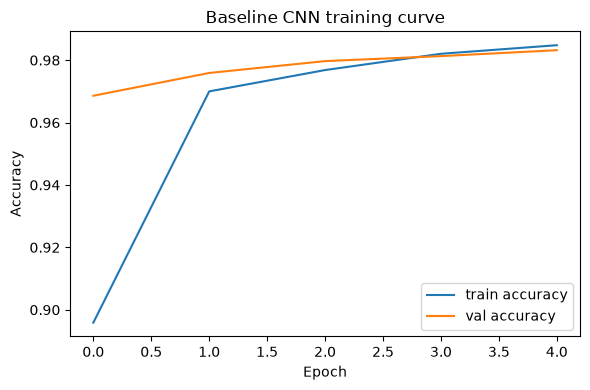

In [72]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Baseline model -- test accuracy: {test_acc:.4f}, test loss: {test_loss:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN training curve")
plt.legend()
plt.tight_layout()
plt.savefig("baseline_training_curve.png", dpi=110)
plt.show()

## Step 2 - Experiment with training parameters

Try changing each of the following, one at a time, and note the effect on
accuracy, training time, and model size:

- Learning rate
- Optimizer (SGD vs Adam vs RMSprop)
- Number of epochs
- Batch size
- Activation functions
- Number of filters/neurons per layer
- Dropout
- Number of layers

**TODO 3:** Complete `run_experiment()` below (build, train, and evaluate a
model, timing the training run and counting its trainable parameters), then
add your own entries to the `results` list - at least one experiment per
bullet point above. Reuse `build_model()` and `run_experiment()`; don't
rewrite the training loop by hand for each one.

In [ ]:
import pandas as pd

def count_params(m):
    return int(np.sum([tf_keras.backend.count_params(w) for w in m.trainable_weights]))

def run_experiment(name, optimizer, epochs=3, batch_size=64, activation="relu",
                    num_filters1=8, num_filters2=16, dense_units=32, dropout=0.0):
    # TODO 3a: build the model with the given hyperparameters
    m = None
    

    # TODO 3b: compile it (same loss/metric as Step 1) with the given optimizer

    # TODO 3c: time a call to m.fit() with the given epochs/batch_size (verbose=0)
    start = time.time()
    elapsed = None

    # TODO 3d: evaluate on the test set and count trainable params
    acc = None
    n_params = None

    return {
        "experiment": name,
        "test_accuracy": round(acc, 4),
        "train_time_sec": round(elapsed, 1),
        "trainable_params": n_params,
    }



#####################################################################################

def run_experiment(name, optimizer, epochs=3, batch_size=64,
                   activation="relu",
                   num_filters1=8,
                   num_filters2=16,
                   dense_units=32,
                   dropout=0.0):

    m = build_model(
        activation=activation,
        num_filters1=num_filters1,
        num_filters2=num_filters2,
        dense_units=dense_units,
        dropout=dropout
    )

    m.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start = time.time()

    m.fit(
        x_train,
        y_train,
        epochs=epochs,
        batch_size=batch_size,
        verbose=0
    )

    elapsed = time.time() - start

    _, acc = m.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    n_params = count_params(m)

    return {
        "experiment": name,
        "test_accuracy": round(acc, 4),
        "train_time_sec": round(elapsed, 1),
        "trainable_params": n_params,
    }

# TODO 3e: add at least one run_experiment(...) call per bullet point above

# For this part, we decided to test the optimizers (adam, SGD or RMSprop).
# We also tested number of epochs ()
results = []

results.append(run_experiment(
    "Baseline Adam", optimizer="adam"
))

results.append(run_experiment(
    "SGD", optimizer="sgd"
))

results.append(run_experiment(
    "RMSprop", optimizer="rmsprop"
))

for i in [5, 10, 20]:
    results.append(run_experiment(
        f"{i} epochs", optimizer="adam", epochs=i
    ))

for i in [128, 256, 512]:
    results.append(run_experiment(
        f"Batch {i}", optimizer="adam", batch_size=i
    ))

results.append(run_experiment(
    "Sigmoid", optimizer="adam", activation="sigmoid"
))

results.append(run_experiment(
    "Relu", optimizer="adam", activation="relu"
))

results.append(run_experiment(
    "Tanh", optimizer="adam", activation="tanh"
))

results.append(run_experiment(
    "More filters",
    optimizer="adam",
    num_filters1=16,
    num_filters2=32
))

results.append(run_experiment(
    "Dense 64",
    optimizer="adam",
    dense_units=64
))

results.append(run_experiment(
    "Dropout 0.3",
    optimizer="adam",
    dropout=0.3
))

results_df = pd.DataFrame(results)
print(results_df)

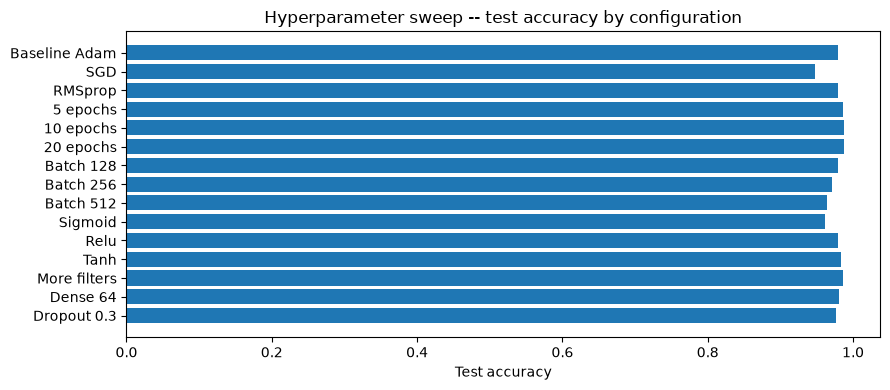

Best configuration in this sweep:
experiment          20 epochs
test_accuracy          0.9877
train_time_sec          183.7
trainable_params        14410
Name: 5, dtype: object


In [8]:
plt.figure(figsize=(9, 4))
plt.barh(results_df["experiment"], results_df["test_accuracy"])
plt.xlabel("Test accuracy")
plt.title("Hyperparameter sweep -- test accuracy by configuration")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("hyperparameter_sweep.png", dpi=110)
plt.show()

best_row = results_df.loc[results_df["test_accuracy"].idxmax()]
print("Best configuration in this sweep:")
print(best_row)

## Step 3 - Create and test your own dataset

1. Draw all 10 digits (phone app, or on paper + photo).
2. Save them into the `my_digits/` folder as `digit_0.png`, `digit_1.png`,
   ... `digit_9.png` (one file per digit, filename matches the digit drawn).
3. Complete the preprocessing function below so your photos match MNIST's
   format **exactly**:
   - Convert to grayscale.
   - Resize to 28x28.
   - MNIST digits are **white strokes on a black background** - a normal
     photo of pen-on-paper is the opposite (dark strokes on a light
     background), so you'll need to invert it.
   - Normalize to [0, 1].

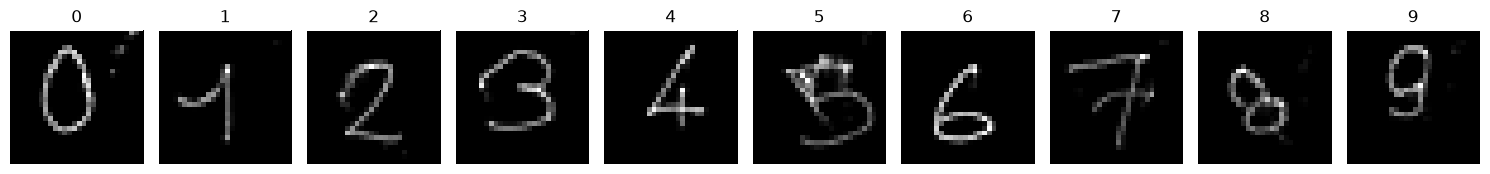

In [75]:
from PIL import Image
import os
import numpy as np
import matplotlib.pyplot as plt


def load_and_preprocess_digit(path):
    # TODO 4: grayscale -> resize to 28x28 -> invert -> normalize to [0,1]
    arr = None
    return arr

def load_and_preprocess_digit(path):

    img = Image.open(path).convert("L")
    img = img.resize((28, 28))

    arr = np.array(img)

    arr = 255 - arr

    arr = arr.astype(np.float32) / 255.0

    return arr


digits_dir = "my_digits"
my_x, my_y = [], []
for digit in range(10):
    path = os.path.join(digits_dir, f"digit_{digit}.png")
    my_x.append(load_and_preprocess_digit(path))
    my_y.append(digit)

my_x = np.array(my_x)[..., np.newaxis]
my_y = np.array(my_y)

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i, ax in enumerate(axes):
    ax.imshow(my_x[i, :, :, 0], cmap="gray")
    ax.set_title(str(my_y[i]))
    ax.axis("off")
plt.tight_layout()
plt.savefig("my_digits_preview.png", dpi=110)
plt.show()

**TODO 5:** Evaluate your trained model on your own digits and print
whether each prediction was correct. Expect worse accuracy than on MNIST's
test set - be ready to explain why (distribution shift: your handwriting,
pen, and camera/scanner don't match how MNIST's ~70,000 images were
collected).

In [77]:
# TODO 5: evaluate model on (my_x, my_y), then print true vs. predicted
# digit for each of the 10 images, with an OK/WRONG marker
my_acc = None
# print(f"Accuracy on my own digits: {my_acc:.4f}  (MNIST test accuracy was {test_acc:.4f})")

# we start a timer to measure the time taken for predictions
start_time = time.time()

predictions = model.predict(my_x, verbose=0)
predicted_digits = np.argmax(predictions, axis=1)

# we stop the timer and print the elapsed time
elapsed_time = time.time() - start_time
elapsed_time_10 = elapsed_time / 10
print(f"Time taken for predictions: {elapsed_time:.4f} seconds")
print(f"Time taken for predictions by 10 images: {elapsed_time_10:.4f} seconds")


my_acc = np.mean(predicted_digits == my_y)

print(
    f"Accuracy on my own digits: "
    f"{my_acc:.4f}  "
    f"(MNIST test accuracy was {test_acc:.4f})"
)

for true_digit, predicted_digit in zip(my_y, predicted_digits):

    status = "OK" if true_digit == predicted_digit else "WRONG"

    print(
        f"True: {true_digit} | "
        f"Predicted: {predicted_digit} | {status}"
    )

Time taken for predictions: 0.9440 seconds
Time taken for predictions by 10 images: 0.0944 seconds
Accuracy on my own digits: 0.7000  (MNIST test accuracy was 0.9832)
True: 0 | Predicted: 9 | WRONG
True: 1 | Predicted: 1 | OK
True: 2 | Predicted: 2 | OK
True: 3 | Predicted: 3 | OK
True: 4 | Predicted: 4 | OK
True: 5 | Predicted: 8 | WRONG
True: 6 | Predicted: 2 | WRONG
True: 7 | Predicted: 7 | OK
True: 8 | Predicted: 8 | OK
True: 9 | Predicted: 9 | OK


In [ ]:
# In addition to the hyperparameter alone test, we also test combinations of hyperparameters :
def run_experiment(name, optimizer="adam",
                   epochs=5, batch_size=64,
                   activation="relu",
                   num_filters1=8,
                   num_filters2=16,
                   num_filters3=32,
                   num_conv_layers=2,
                   dense_units=32,
                   dense_units2=16,
                   num_dense_layers=1,
                   dropout=0.0):

    print("\n================================")
    print("Experiment:", name)
    print("================================")

    # Build model
    m = build_model(
        activation=activation,
        num_filters1=num_filters1,
        num_filters2=num_filters2,
        num_filters3=num_filters3,
        num_conv_layers=num_conv_layers,
        dense_units=dense_units,
        dense_units2=dense_units2,
        num_dense_layers=num_dense_layers,
        dropout=dropout
    )

    # Compile
    m.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Train model
    start = time.time()

    history = m.fit(
        x_train,
        y_train,
        epochs=epochs,
        batch_size=batch_size,
        verbose=0
    )

    train_time = time.time() - start

    # MNIST test accuracy
    _, test_acc = m.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    # Predictions on personal digits
    
    predictions = m.predict(my_x, verbose=0)
    predicted_digits = np.argmax(predictions, axis=1)

    # Own data accuracy
    my_acc = np.mean(predicted_digits == my_y)

    # Warm-up
    m.predict(my_x, verbose=0)

    # Inference time for 10 images
    start_time = time.perf_counter()

    # Predict each image separately
    for i in range(len(my_x)):
        m.predict(my_x[i:i+1], verbose=0)

    elapsed_time = time.perf_counter() - start_time
    elapsed_time_10 = elapsed_time / 10

    # Average inference time per image
    avg_time_ms = elapsed_time * 1000 / len(my_x)

    # Memory size
    n_params = m.count_params()
    memory_kb = n_params * 4 / 1024

    print(f"MNIST test accuracy: {test_acc:.4f}")
    print(f"My digits accuracy: {my_acc:.4f}")
    print(f"Memory size (weights): {memory_kb:.2f} KB")
    print(f"Average inference time: {avg_time_ms:.3f} ms/image")
    print(f"Inference time (10 images): {elapsed_time_10:.3f} s")

    # Print predictions for all digits
    print("\nPredictions on my digits:")


    for true_digit, predicted_digit in zip(my_y, predicted_digits):

        status = "OK" if true_digit == predicted_digit else "WRONG"

        print(
            f"True: {true_digit} | "
            f"Predicted: {predicted_digit} | "
            f"{status}"
        )

    return {
        "experiment": name,
        "test_accuracy": round(test_acc, 4),
        "val_accuracy": my_acc,
        "train_time_sec": round(train_time, 1),
        "inference_ms_image": round(avg_time_ms, 3),
        "trainable_params": n_params,
        "weights_memory_kb": round(memory_kb, 2),
        "model": m,
        "history": history
    }


In [ ]:
# We can now test different configurations of models and try these models on our own digits.

# 1. Baseline model
results.append(run_experiment(
    "Baseline",
    optimizer="adam",
    epochs=5
))

# 2. Fewer convolutional filters
results.append(run_experiment(
    "Fewer filters",
    optimizer="adam",
    epochs=5,
    num_filters1=4,
    num_filters2=8
))

# 3. More convolutional filters
results.append(run_experiment(
    "More filters",
    optimizer="adam",
    epochs=5,
    num_filters1=16,
    num_filters2=32
))

# 4. Only one convolutional layer
results.append(run_experiment(
    "1 Conv layer",
    optimizer="adam",
    epochs=5,
    num_conv_layers=1
))

# 5. Three convolutional layers
results.append(run_experiment(
    "3 Conv layers",
    optimizer="adam",
    epochs=5,
    num_conv_layers=3,
    num_filters3=32
))

# 6. Smaller Dense layer
results.append(run_experiment(
    "Dense 16",
    optimizer="adam",
    epochs=5,
    dense_units=16
))

# 7. Two Dense layers
results.append(run_experiment(
    "2 Dense layers",
    optimizer="adam",
    epochs=5,
    num_dense_layers=2,
    dense_units=32,
    dense_units2=16
))


Experiment: Baseline
MNIST test accuracy: 0.9852
My digits accuracy: 0.6000
Memory size (weights): 56.29 KB
Average inference time: 49.587 ms/image
Inference time (10 images): 0.050 s

Predictions on my digits:
True: 0 | Predicted: 9 | WRONG
True: 1 | Predicted: 7 | WRONG
True: 2 | Predicted: 2 | OK
True: 3 | Predicted: 3 | OK
True: 4 | Predicted: 4 | OK
True: 5 | Predicted: 5 | OK
True: 6 | Predicted: 2 | WRONG
True: 7 | Predicted: 7 | OK
True: 8 | Predicted: 5 | WRONG
True: 9 | Predicted: 9 | OK

Experiment: Fewer filters
MNIST test accuracy: 0.9817
My digits accuracy: 0.3000
Memory size (weights): 27.73 KB
Average inference time: 47.354 ms/image
Inference time (10 images): 0.047 s

Predictions on my digits:
True: 0 | Predicted: 7 | WRONG
True: 1 | Predicted: 1 | OK
True: 2 | Predicted: 1 | WRONG
True: 3 | Predicted: 3 | OK
True: 4 | Predicted: 1 | WRONG
True: 5 | Predicted: 7 | WRONG
True: 6 | Predicted: 2 | WRONG
True: 7 | Predicted: 7 | OK
True: 8 | Predicted: 2 | WRONG
True: 9 |

In [ ]:
comparison = pd.DataFrame([
    {
        key: value
        for key, value in result.items()
        if key not in ["model", "history"]
    }
    for result in results
])

display(comparison)

save_path = "model_results_df.csv"
results_df.to_csv(save_path, index=False)



,experiment,test_accuracy,train_time_sec,inference_ms_image,trainable_params,weights_memory_kb,val_accuracy
0,Baseline,0.9838,26.4,47.924,14410,56.29,NaN
1,Fewer filters,0.9808,33.5,45.462,7098,27.73,NaN
2,More filters,0.9876,44.8,50.056,30762,120.16,NaN
3,1 Conv layer,0.9826,26.2,50.084,43706,170.73,NaN
4,3 Conv layers,0.9895,38.6,54.416,31850,124.41,NaN
5,Dense 16,0.9821,35.8,52.118,7834,30.60,NaN
6,2 Dense layers,0.9842,35.1,54.982,14778,57.73,NaN
7,Baseline,0.9867,29.3,48.968,14410,56.29,NaN
8,Fewer filters,0.9784,35.5,62.626,7098,27.73,NaN
9,More filters,0.9873,52.7,55.114,30762,120.16,NaN


,experiment,test_accuracy,train_time_sec,inference_ms_image,trainable_params,weights_memory_kb,val_accuracy
0,Baseline,0.9838,26.4,47.924,14410,56.29,NaN
1,Fewer filters,0.9808,33.5,45.462,7098,27.73,NaN
2,More filters,0.9876,44.8,50.056,30762,120.16,NaN
3,1 Conv layer,0.9826,26.2,50.084,43706,170.73,NaN
4,3 Conv layers,0.9895,38.6,54.416,31850,124.41,NaN
5,Dense 16,0.9821,35.8,52.118,7834,30.60,NaN
6,2 Dense layers,0.9842,35.1,54.982,14778,57.73,NaN
7,Baseline,0.9867,29.3,48.968,14410,56.29,NaN
8,Fewer filters,0.9784,35.5,62.626,7098,27.73,NaN
9,More filters,0.9873,52.7,55.114,30762,120.16,NaN


In [67]:
results_df = pd.read_csv("model_comparison.csv")
results_df

,experiment,test_accuracy,train_time_sec,inference_ms_image,trainable_params,weights_memory_kb,val_accuracy
0,Baseline,0.9869,28.8,49.587,14410,56.29,0.5
1,Fewer filters,0.9817,34.7,47.354,7098,27.73,0.3
2,More filters,0.9868,45.2,49.024,30762,120.16,0.5
3,1 Conv layer,0.9792,27.6,51.687,43706,170.73,0.2
4,3 Conv layers,0.9881,36.7,53.862,31850,124.41,0.4
5,Dense 16,0.9826,34.3,56.546,7834,30.60,0.8
6,2 Dense layers,0.9800,41.2,57.828,14778,57.73,0.5


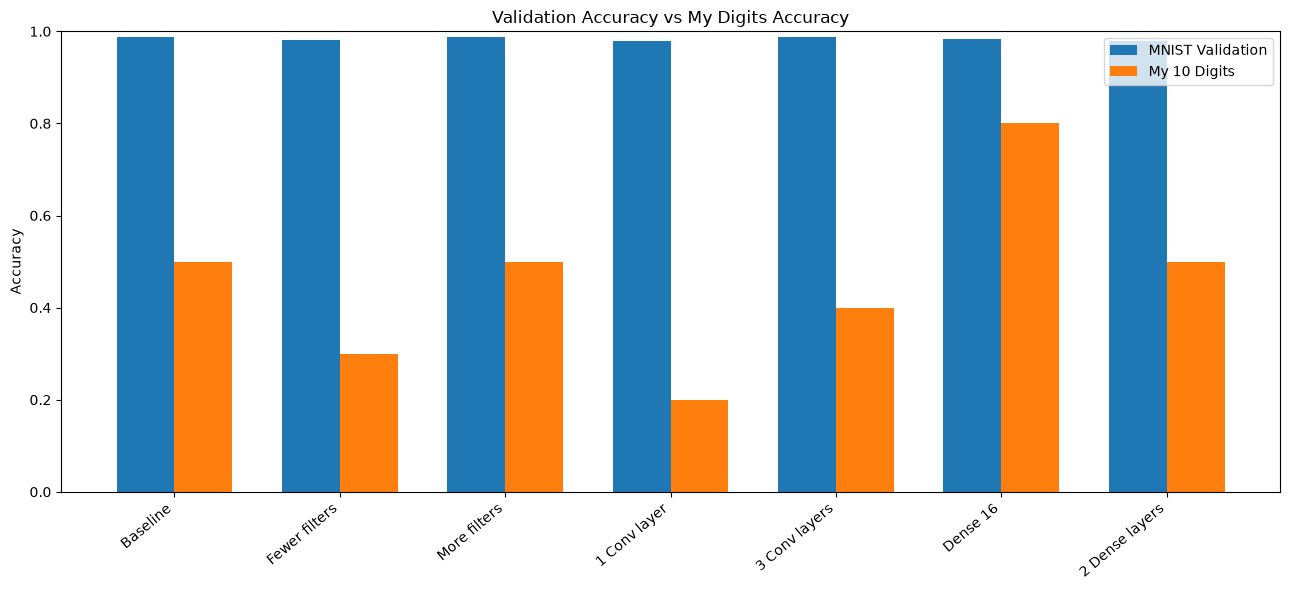

In [68]:
x = np.arange(len(results_df))
width = 0.35

plt.figure(figsize=(13, 6))

plt.bar(
    x - width/2,
    results_df["test_accuracy"],
    width,
    label="MNIST Validation"
)

plt.bar(
    x + width/2,
    results_df["val_accuracy"],
    width,
    label="My 10 Digits"
)

plt.xticks(
    x,
    results_df["experiment"],
    rotation=40,
    ha="right"
)

plt.ylabel("Accuracy")
plt.title("Validation Accuracy vs My Digits Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

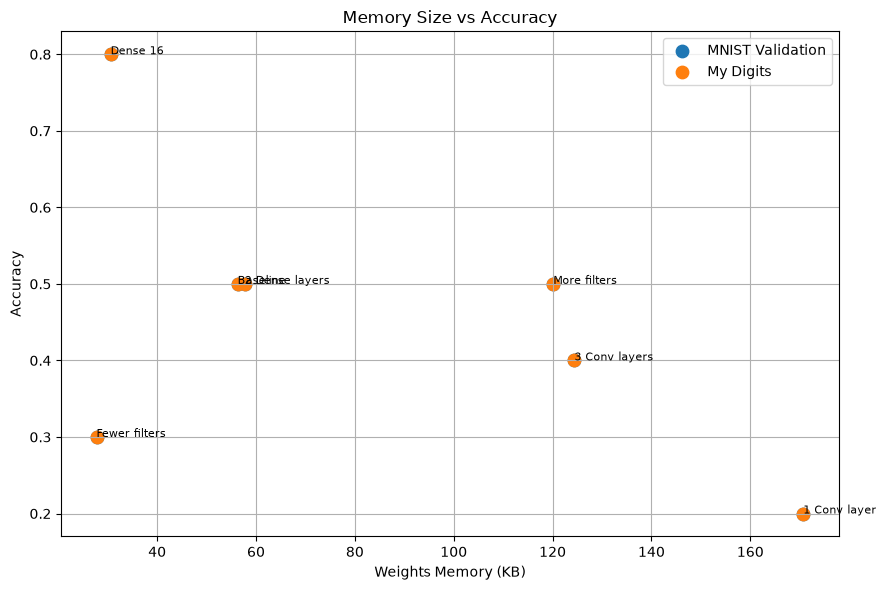

In [69]:
plt.figure(figsize=(9, 6))

plt.scatter(
    results_df["weights_memory_kb"],
    results_df["val_accuracy"],
    label="MNIST Validation",
    s=80
)

plt.scatter(
    results_df["weights_memory_kb"],
    results_df["val_accuracy"],
    label="My Digits",
    s=80
)

for _, row in results_df.iterrows():
    plt.annotate(
        row["experiment"],
        (
            row["weights_memory_kb"],
            row["val_accuracy"]
        ),
        fontsize=8
    )

plt.xlabel("Weights Memory (KB)")
plt.ylabel("Accuracy")
plt.title("Memory Size vs Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [45]:
baseline_acc = results_df.loc[
    results_df["experiment"] == "Baseline",
    "val_accuracy"
].iloc[0]

candidates = results_df[
    results_df["val_accuracy"] >= baseline_acc - 0.01
]

best_row = candidates.sort_values(
    "weights_memory_kb"
).iloc[0]

best_name = best_row["experiment"]

best_model = next(
    result["model"]
    for result in results
    if result["experiment"] == best_name
)

print("Best model:", best_name)
print("My digits accuracy:", best_row["val_accuracy"])
print("Memory size:", best_row["weights_memory_kb"], "KB")

best_model.save("best_mnist_model.h5")

Best model: Dense 16
My digits accuracy: 0.8
Memory size: 30.6 KB


/home/student/anaconda3/envs/machine_embedded/lib/python3.11/site-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [ ]:
# When then try on different model architectures :
# especially on Mini-SqueezeNet and Mini-MobileNet as suggested.

In [ ]:
# Architecture 1: Baseline CNN
def baseline_cnn():
    return tf_keras.models.Sequential([
        tf_keras.layers.Input(shape=(28, 28, 1)),
        tf_keras.layers.Conv2D(8, 3, activation="relu"),
        tf_keras.layers.MaxPooling2D(2),
        tf_keras.layers.Conv2D(16, 3, activation="relu"),
        tf_keras.layers.MaxPooling2D(2),
        tf_keras.layers.Flatten(),
        tf_keras.layers.Dense(32, activation="relu"),
        tf_keras.layers.Dense(10, activation="softmax")
    ])


# Architecture 2: Mini-SqueezeNet
def mini_squeezenet():
    inputs = tf_keras.layers.Input(shape=(28, 28, 1))

    x = tf_keras.layers.Conv2D(8, 3, activation="relu")(inputs)
    x = tf_keras.layers.MaxPooling2D(2)(x)

    # Fire module
    squeeze = tf_keras.layers.Conv2D(4, 1, activation="relu")(x)

    expand1 = tf_keras.layers.Conv2D(
        8, 1, activation="relu", padding="same"
    )(squeeze)

    expand3 = tf_keras.layers.Conv2D(
        8, 3, activation="relu", padding="same"
    )(squeeze)

    x = tf_keras.layers.Concatenate()([expand1, expand3])
    x = tf_keras.layers.MaxPooling2D(2)(x)

    x = tf_keras.layers.Flatten()(x)
    x = tf_keras.layers.Dense(32, activation="relu")(x)

    outputs = tf_keras.layers.Dense(10, activation="softmax")(x)

    return tf_keras.models.Model(inputs, outputs)


# Architecture 3: Mini-MobileNet
def mini_mobilenet():
    return tf_keras.models.Sequential([
        tf_keras.layers.Input(shape=(28, 28, 1)),
        tf_keras.layers.Conv2D(8, 3, activation="relu"),
        tf_keras.layers.MaxPooling2D(2),
        tf_keras.layers.SeparableConv2D(
            16, 3, activation="relu"
        ),
        tf_keras.layers.MaxPooling2D(2),
        tf_keras.layers.Flatten(),
        tf_keras.layers.Dense(32, activation="relu"),
        tf_keras.layers.Dense(10, activation="softmax")
    ])

In [ ]:
# We create an experiment function to these these :

In [54]:
def run_experiment(name, build_model, epochs=5, batch_size=64):

    model = build_model()

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Train model
    start = time.time()

    history = model.fit(
        x_train,
        y_train,
        epochs=epochs,
        batch_size=batch_size,
        verbose=0
    )

    train_time = time.time() - start


    # Test on my 10 digits
    predictions = model.predict(my_x, verbose=0)
    predicted_digits = np.argmax(predictions, axis=1)

    my_acc = np.mean(predicted_digits == my_y)

    # Average inference time on 10 images
    model.predict(my_x, verbose=0)  # Warm-up

    start = time.perf_counter()

    for i in range(len(my_x)):
        model(my_x[i:i+1], training=False)

    avg_time_ms = (
        (time.perf_counter() - start) * 1000 / len(my_x)
    )

    # Memory size (float32 weights)
    n_params = model.count_params()
    memory_kb = n_params * 4 / 1024

    print(f"\n{name}")
    print(f"Validation accuracy: {my_acc:.4f}")
    print(f"Memory: {memory_kb:.2f} KB")

    return {
        "experiment": name,
        "val_accuracy": round(my_acc, 4),
        "train_time_sec": round(train_time, 1),
        "inference_ms_image": round(avg_time_ms, 3),
        "trainable_params": n_params,
        "weights_memory_kb": round(memory_kb, 2)
    }

In [ ]:
# We can now run experiments on these three architectures :

In [74]:
results_step6 = []

results_step6.append(run_experiment(
    "Baseline CNN",
    baseline_cnn,
    epochs=5
))

results_step6.append(run_experiment(
    "Mini-SqueezeNet",
    mini_squeezenet,
    epochs=5
))

results_step6.append(run_experiment(
    "Mini-MobileNet",
    mini_mobilenet,
    epochs=5
))


Baseline CNN
Validation accuracy: 0.8000
Memory: 56.29 KB

Mini-SqueezeNet
Validation accuracy: 0.3000
Memory: 75.18 KB

Mini-MobileNet
Validation accuracy: 0.7000
Memory: 52.57 KB


In [56]:
comparison_step6 = pd.DataFrame(results_step6)

display(comparison_step6)

,experiment,val_accuracy,train_time_sec,inference_ms_image,trainable_params,weights_memory_kb
0,Baseline CNN,0.6,27.1,4.253,14410,56.29
1,Mini-SqueezeNet,0.6,42.6,9.129,19246,75.18
2,Mini-MobileNet,0.8,38.2,4.582,13458,52.57


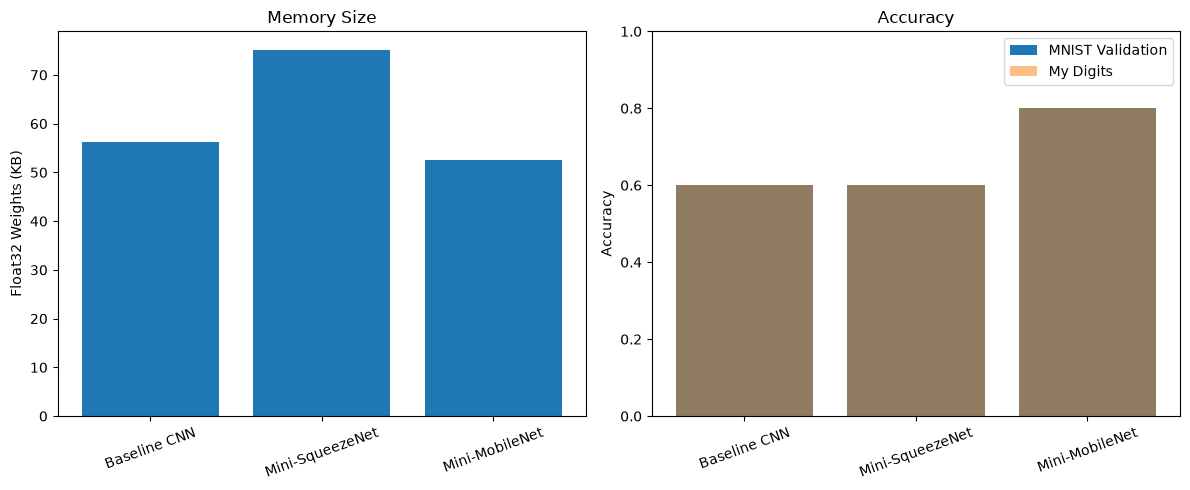

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(
    comparison_step6["experiment"],
    comparison_step6["weights_memory_kb"]
)
axes[0].set_title("Memory Size")
axes[0].set_ylabel("Float32 Weights (KB)")

axes[1].bar(
    comparison_step6["experiment"],
    comparison_step6["val_accuracy"],
    label="MNIST Validation"
)

axes[1].bar(
    comparison_step6["experiment"],
    comparison_step6["val_accuracy"],
    alpha=0.5,
    label="My Digits"
)

axes[1].set_title("Accuracy")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
axes[1].legend()

for ax in axes:
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## Step 4 - Save the trained model

**TODO 6:** Save the model in both `.h5` and `SavedModel` format
(`model.save("mnist_cnn.h5")` and `model.save("mnist_cnn_savedmodel")` - a
path with no recognized extension saves as `SavedModel`). You'll load this
exact model again in Lab 2.3, so keep both files/folders safe.

In [11]:
# TODO 6: save the model as mnist_cnn.h5 and as a SavedModel export

model.save("mnist_cnn.h5")
model.save("mnist_cnn_savedmodel")

/home/student/anaconda3/envs/machine_embedded/lib/python3.11/site-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


INFO:tensorflow:Assets written to: mnist_cnn_savedmodel/assets


INFO:tensorflow:Assets written to: mnist_cnn_savedmodel/assets


## Discussion Topics

Answer in a few sentences each:

1. Which single hyperparameter gave you the biggest accuracy gain (or loss)?
2. Where did your own handwritten digits fail, and why do you think that is?
3. What's the tradeoff between model size and accuracy in your experiments?

#### 1. Which single hyperparameter gave you the biggest accuracy gain (or loss)?
When we test diverse parameters we discover that the increasing of epoch numbers helps the improvement of the accuracy. That is understandable since every epoch is supposed to reset weights and biases in order to improve accuracy. The activation function as well as the optimizer are important in the accuracy changes. More specifically, SGD is the less effective hyperparameter in our context.
Finally, the batch size is decreasingly effective : the more the batch size, the less the accuracy.

##### 2.Where did your own handwritten digits fail, and why do you think that is ?

The first basic CNN setting we made achieved 70% accuracy on my own digits, compared to 98.32% with the MNIST set.
The model mispredicted 0 as 9, 5 as 8 and 6 as 2.
For 0 as 9, it is obvious that these round figures misled the model, for 5 and 8, it is also explainable by the shape of 5 that can be read as an "unclosed" 8, for the 6 as 2, we can analyse that my 6 as a real flat base and that it has a diagonal line that can be related to the 2 diagonal line.
I talk about this first basic CNN because everytime I reran the model for test, the accuracy changed and the wrong prediction as well.
It appears the the training is not enoughly long to have a fixed model. The number epochs, is certainly to be increased to increased the accuracy as we've seen previously.

#### 3. What's the tradeoff between model size and accuracy in your experiments?
The baseline CNN contains 14,410 trainable parameters and achieves 98.32% accuracy on the MNIST test set.

This demonstrates that a relatively small neural network can achieve high accuracy on a handwritten digit recognition task.

Increasing the number of convolutional filters or dense neurons would increase the model's capacity to learn complex features, but it would also increase memory usage, computational cost and potentially training time.

Conversely, reducing the number of parameters would produce a smaller and potentially faster model, but it could decrease classification accuracy.

For embedded systems, the objective is to find a good balance between model size, inference speed and accuracy.